# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

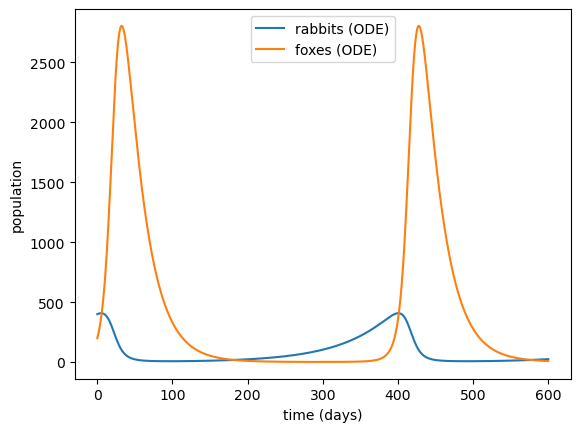

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

In [3]:
def kmc(R0, F0, t_end, rng):
    t, R, F, = 0.0, R0, F0
    out = [(t, R, F)]
    
    while t < t_end:
        c = np.cumsum([k1 * R, k2 * R * F, k3 * R * F, k4 * F])
        Q = c[-1]
        if Q == 0:
            break
            
        event = np.searchsorted(c, rng.random() * Q, side = "right")
        t += -np.log(1 - rng.random()) / Q
        
        dR, dF = [(1, 0), (-1, 0), (0, 1), (0, -1)][event]
        R, F = R + dR, F + dF
        
        if R < 0 or F < 0:
            raise ValueError(f"negative population: R = {R}, F = {F}")
        out.append((t, R, F))
            
    times, rabbits, foxes = np.array(out).T
    return times, rabbits.astype(int), foxes.astype(int)

rng = np.random.default_rng(1)
start = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
elapsed = time.perf_counter() - start
print(f"{len(times) - 1} events in {elapsed:.2f} s")

17362 events in 0.25 s


In [4]:
def second_peak(times, foxes):
    after = times > 200
    
    t = np.concatenate(([200.0], times[after]))
    f = np.concatenate(([foxes[np.searchsorted(times, 200, side = "right") - 1]], foxes[after]))
    t, f = t[t <= 600], f[t <= 600]
    j = f.argmax()
    return(t[j], f[j]) if f[j] > 100 and 205 <= t[j] <= 595 else None

def many(n, seed = 0):
    rng = np.random.default_rng(seed)
    peak, ext, f600 = [], [], []
    
    for _ in range(n):
        t, R, F = kmc(R0, F0, t_end, rng)
        peak.append(second_peak(t, F) or (np.nan, np.nan))
        ext.append(t[F == 0][0] if (F == 0).any() else np.nan)
        f600.append(F[np.searchsorted(t, 600, side = "right") - 1])
    peak = np.array(peak)
    return peak[:, 0], peak[:, 1], np.array(ext), np.array(f600)

pt, ph, et, f6 = many(100)
print(int(np.sum(~np.isnan(pt))))

34


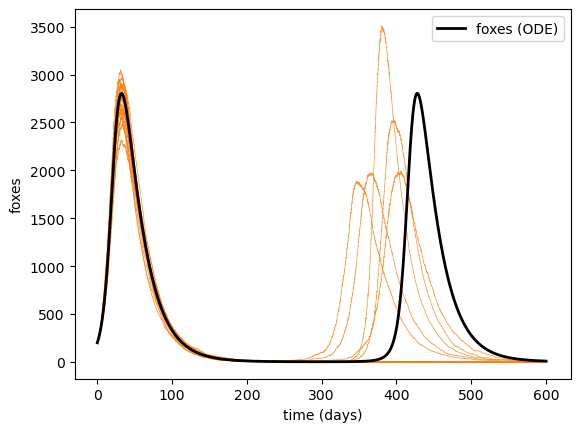

15 of 20 runs lost all of their foxes
extiniction times: 215 to 307 days


In [5]:
plt.figure()
extinct_times = []

for seed in range(20):
    rng = np.random.default_rng(seed)
    times, rabbits, foxes = kmc(R0, F0, t_end, rng)
    plt.step(times, foxes, where="post", lw=0.5, color="C1", alpha=0.8)
    
    if foxes[-1] == 0:
        extinct_times.append(times[np.argmax(foxes == 0)])

plt.plot(t_ode, F_ode, "k", lw = 2, label = "foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("foxes")

plt.legend()
plt.show()

print(f"{len(extinct_times)} of 20 runs lost all of their foxes")
print(f"extiniction times: {min(extinct_times):.0f} to {max(extinct_times):.0f} days")

second peak in 34 of 100 runs
time (days): mean 402.5, median 395.6, IQR 378.7 to 414.9
height (foxes): mean 2373.7, median 2189.5, IQR 1955.5 to 2701.2


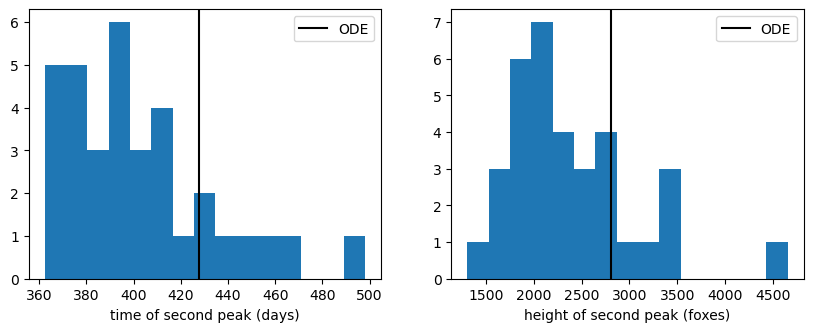

In [6]:
pt, ph, et, f6 = many(100)
ok = ~np.isnan(pt)
print(f"second peak in {ok.sum()} of 100 runs")

for name, a in (("time (days)", pt[ok]), ("height (foxes)", ph[ok])):
    q1, q3 = np.percentile(a, [25, 75])
    print(f"{name}: mean {a.mean():.1f}, median {np.median(a):.1f}, IQR {q1:.1f} to {q3:.1f}")

fig, ax = plt.subplots(1, 2, figsize = (10, 3.5))
ax[0].hist(pt[ok], bins=15)
ax[0].axvline(427.8, color="k", label="ODE")
ax[0].set_xlabel("time of second peak (days)")
ax[0].legend()
ax[1].hist(ph[ok], bins=15)
ax[1].axvline(2804, color="k", label="ODE")
ax[1].set_xlabel("height of second peak (foxes)")
ax[1].legend()
plt.show()

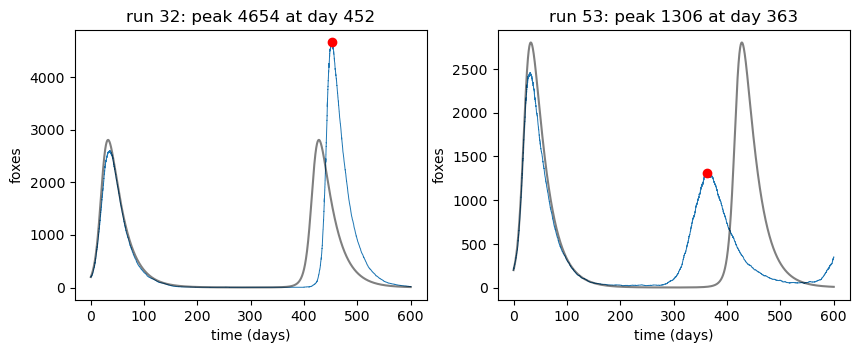

In [7]:
rng = np.random.default_rng(0)
trajectories = [kmc(R0, F0, t_end, rng) for _ in range(100)]

fig, ax = plt.subplots(1, 2, figsize = (10, 3.5))

for a, i in zip(ax, (32, 53)):
    times, rabbits, foxes = trajectories[i]
    t_pk, h_pk = second_peak(times, foxes)
    
    a.step(times, foxes, where="post", lw=0.7)
    a.plot(t_ode, F_ode, "k", alpha=0.5)
    a.plot(t_pk, h_pk, "ro")
    a.set_title(f"run {i}: peak {h_pk} at day {t_pk:.0f}")
    a.set_xlabel("time (days)")
    a.set_ylabel("foxes")
    
plt.show()

In [8]:
for n in (100, 300, 1000, 3000):
    t, h = pt[:n], ph[:n]
    k = np.sum(~np.isnan(t))
    
    standard1 = np.nanstd(t, ddof = 1) / np.sqrt(k)
    standard2 = np.nanstd(h, ddof = 1) / np.sqrt(k)
    
    print(f"{n:5d} runs, {k:4d} peaks | time {np.nanmean(t):6.1f} +- {standard1:4.2f}, IQR {np.nanpercentile(t, 25):.0f}-{np.nanpercentile(t, 75):.0f}"
          f" | height {np.nanmean(h):7.1f} +- {standard2:5.1f}, IQR {np.nanpercentile(h, 25):.0f}-{np.nanpercentile(h, 75):.0f}")

rng = np.random.default_rng(1)

for name, a in (("time", pt), ("height", ph)):
    a = a[~np.isnan(a)]
    q = np.array([np.percentile(rng.choice(a, len(a)), [25, 75]) for _ in range(2000)])
    
    print(name, "quartile SEs:", q.std(axis=0).round(1))

  100 runs,   34 peaks | time  402.5 +- 5.46, IQR 379-415 | height  2373.7 +- 114.4, IQR 1956-2701
  300 runs,   34 peaks | time  402.5 +- 5.46, IQR 379-415 | height  2373.7 +- 114.4, IQR 1956-2701
 1000 runs,   34 peaks | time  402.5 +- 5.46, IQR 379-415 | height  2373.7 +- 114.4, IQR 1956-2701
 3000 runs,   34 peaks | time  402.5 +- 5.46, IQR 379-415 | height  2373.7 +- 114.4, IQR 1956-2701
time quartile SEs: [6.1 9.5]
height quartile SEs: [ 82.1 191.3]


foxes gone by day 600: 67 of 100 runs, p = 0.670 +- 0.047
runs needed for an SE of 0.01: 2,211
runs needed for an SE of 0.001: 221,100


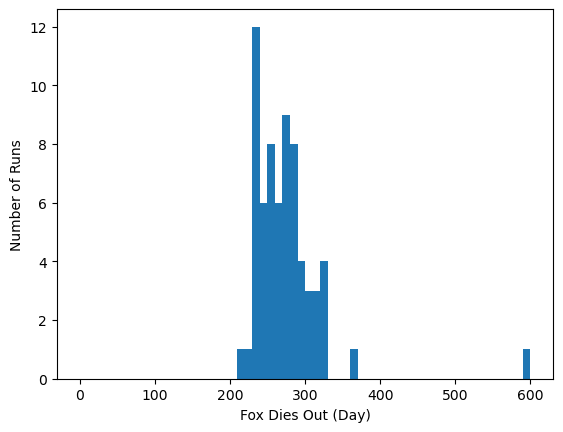

median 268 days, IQR 245 to 289


In [9]:
dead = f6 == 0
p = dead.mean()
se = np.sqrt(p * (1 - p) / len(f6))

print(f"foxes gone by day 600: {dead.sum()} of {len(f6)} runs, p = {p:.3f} +- {se:.3f}")
print(f"runs needed for an SE of 0.01: {p * (1 - p) / 0.01**2:,.0f}")
print(f"runs needed for an SE of 0.001: {p * (1 - p) / 0.001**2:,.0f}")

plt.hist(et[dead], bins = np.arange(0, 601, 10))
plt.xlabel("Fox Dies Out (Day)")
plt.ylabel("Number of Runs")
plt.show()

q1, med, q3 = np.percentile(et[dead], [25, 50, 75])
print(f"median {med:.0f} days, IQR {q1:.0f} to {q3:.0f}")

In [10]:
import math, random

def kmc_fast(R0, F0, t_end, rnd, fixed = False):
    t, R, F = 0.0, R0, F0
    ts, Fs = [t], [F]
    
    while t < t_end:
        a1 = k1 * R
        a2 = a1 + k2 * R * F
        a3 = a2 + k3 * R * F
        Q = a3 + k4 * F
        
        if Q == 0:
            break
            
        x = rnd() * Q
        t += 1 / Q if fixed else -math.log(1 - rnd()) / Q
        
        if x < a1:
            R += 1
        elif x < a2:
            R -= 1
        elif x < a3:
            F += 1
        else:
            F -= 1
        ts.append(t); Fs.append(F)
    return np.array(ts), np.array(Fs)

%timeit kmc(R0, F0, t_end, np.random.default_rng(1))
%timeit kmc_fast(R0, F0, t_end, random.Random(1).random)

def run(fixed, N = 6000):
    rnd = random.Random(int(fixed)).random
    pt, ph, dead = [], [], 0
    
    for _ in range(N):
        t, F = kmc_fast(R0, F0, t_end, rnd, fixed)
        dead += F[np.searchsorted(t, 600, side = "right") - 1] == 0
        pk = second_peak(t, F)
        
        if pk:
            pt.append(pk[0]); ph.append(pk[1])
    return N, dead, np.array(pt), np.array(ph)

def numbers(N, dead, pt, ph):
    k = len(pt)
    p, q = dead / N, k / N
    return [(p, np.sqrt(p * (1 - p) / N)), (q, np.sqrt(q * (1 - q) / N)),
            (pt.mean(), pt.std(ddof=1) / np.sqrt(k)), (ph.mean(), ph.std(ddof=1) / np.sqrt(k))]

names = ["P(foxes gone by day 600)", "fraction with second peak", "mean peak time", "mean peak height"]
for name, (va, sa), (vb, sb) in zip(names, numbers(*run(False)), numbers(*run(True))):
    print(f"{name:26s} random {va:.3f} +- {sa:.3f} | fixed {vb:.3f} +- {sb:.3f} | {(va - vb) / np.hypot(sa, sb):+.1f} sigma")

225 ms ± 11.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
13.9 ms ± 89.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
P(foxes gone by day 600)   random 0.703 +- 0.006 | fixed 0.690 +- 0.006 | +1.6 sigma
fraction with second peak  random 0.314 +- 0.006 | fixed 0.326 +- 0.006 | -1.4 sigma
mean peak time             random 401.651 +- 0.722 | fixed 400.989 +- 0.658 | +0.7 sigma
mean peak height           random 2378.607 +- 14.077 | fixed 2381.401 +- 13.381 | -0.1 sigma


In [ ]:
pt, ph, et, f6 = many(10000)
np.savetxt("second_peak.txt", np.column_stack([pt, ph]))
np.savetxt("extinction.txt", np.column_stack([et, f6]))

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:*

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

In [ ]:
# a) There are four entries, such as fox/rabbit is born/dies. A rate is then created for each of these different entries, and the total rate is Q. 

In [ ]:
# b) The run has 17,362 events and it took 0.1 seconds.
#  The KMC Trajectory jumps by whole numbers, while the ODE is not afraid to use fractions

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

In [ ]:
# a) The 20 trajectories all follow the ODE when larger, and spread apart near the trough where only a few foxes are remaining.
# b) Once the fox trajectory reaches zero, the foxes are gone and rabbits grow uncontrollably. If the rabbits trajectory is 0, then the rabbits are gone and the foxes will die off. Nothing can recover from death.
# c) Near the trough, which is at 200 to 300 days. That is where the number of rabbits is very low and the foxes can easily die off if one or two more members of their species die off

*Answer:*

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

In [ ]:
# a) The second peak is at 34 to 100 runs, with a mean residence time of 402 seconds, a median of 396, an IQR from 379 to 415 days, and a height of 2190
# b) ODE peaked much later and a higher magnitude than the peak of the KMC. They differ because the foxes that die out at the first trough never reach the second peak.
# c) It returns the peak of curves with meaningful data, but does not if the peak is too low or late. No trajectory can be found with this information

*Answer:*

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

In [ ]:
# The mean time stays somewhere around 402 days and the mean height near 2350 to 2375 foxes as the run goes from 100 to 3000.
# The standard error falls as the equation given. Time of standard error is from 5.5 to 1 day and the height is from 114 to 19.5 foxes.
# The final values are 402 +/- 1 days and 2360 +/- 20 foxes

*Answer:*

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

In [ ]:
# The probability is 0.691 +/- 0.008
# The run needed for +/- 1 percentage point is 2,100 and the run needed for 0.1 is 2360
# The foxes die out between 200 and 300 (the trough)

*Answer:*

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

<!-- The goal of my catalytic converter project is to make the design more sustainable by using less platinum-group metal and decreasing the surface area. The ODE for the surface coverage of the nitric and carbonic oxides, if assumed to be a well-mixed surface, would have many sites. The "events" would be one of the oxides absorbing on one of the free sites. The events can then be deactivated by poisoning the site and performing a seperate ODE of deabsorption process. I would then use the KMC for the overall continuum model of exhaust gasses leaving, since there is an enormous amount of molecules involved. -->

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

In [ ]:
# a) The new trajectory was 10 to 16 times faster by replacing the numpy calls that were in the loop with plain, simple arithmatic.

# c) With 6000 runs of each, there was no difference created was bigger than the uncertainty value. This was because at the mean residence time is the same

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.